In [1]:
import numpy as np
import polars as pl
import typol as tp
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split

from Answer import Answer, AnswerWithoutQ11, AnswerQ11NullsAsOnes, AnswerWithPredictedAndActualQ11, AnswerParts1_6, AnswerWithPredictedAndActualQ1

In [2]:
labels = {
    1: "None",
    2: "1...2",
    3: "3...4",
    4: "5...6",
    5: "6...10",
    6: "10...20",
    7: ">20",
}

In [3]:
# TODO Predict a person's reading habits (how much/often they read) according to their answers
def predict_habits(data: tp.DataFrame[AnswerQ11NullsAsOnes]) -> tp.DataFrame[AnswerWithPredictedAndActualQ11]:
    # we're trying to predict the enum HowManyBooksReadInTheLastSixMonths aka Question 11
    training_data: tp.DataFrame[AnswerWithoutQ11] = data.transform(AnswerWithoutQ11)
    X_train, X_test, y_train, y_test = train_test_split(
        training_data.dataframe, data[Answer.Q11_1].to_list(), test_size=0.20, random_state=0
    )
    X_train = tp.DataFrame(AnswerWithoutQ11, X_train)
    # it wouldn't do to just train on X_train and y_train because the model would correctly,
    # but not very usefully, learn that empty answers => non-reader
    books_read_predictor: RandomForestClassifier = RandomForestClassifier()
    books_read_predictor.fit(X_train, y_train)
    predictions: np.ndarray[tuple[int], np.dtype[np.int32]] = books_read_predictor.predict(X_test)
    as_dict = {
        "Predicted": predictions,
        "Actual": y_test,
    }
    results = tp.DataFrame(AnswerWithPredictedAndActualQ11, as_dict)
    return results


In [4]:
def predict_is_reader_parts_1_6(data: tp.DataFrame[Answer]) -> tp.DataFrame[AnswerWithPredictedAndActualQ1]:
    # we're trying to predict the enum HowManyBooksReadInTheLastSixMonths aka Question 11
    training_data: tp.DataFrame[AnswerWithoutQ11] = data.transform(AnswerWithoutQ11)
    X_train, X_test, y_train, y_test = train_test_split(
        training_data.dataframe, data[Answer.Q11_1].to_list(), test_size=0.20, random_state=0
    )
    X_train = tp.DataFrame(AnswerWithoutQ11, X_train)
    # we need to predict whether a person considers themself a reader.
    # we can only predict this based on the answers they give in parts 1 and 6,
    # because they're the only parts that non-readers and readers both fill in
    X_train_parts_1_6 = X_train.transform(AnswerParts1_6)
    y_train_reader_or_not = []
    for i in range(0, len(y_train)):
        if y_train[i] == 1:
            y_train_reader_or_not.append(0)
        else:
            y_train_reader_or_not.append(1)
    y_test_reader_or_not = []
    for i in range(0, len(y_test)):
        if y_train[i] == 1:
            y_test_reader_or_not.append(0)
        else:
            y_test_reader_or_not.append(1)
    is_reader_predictor: RandomForestClassifier = RandomForestClassifier()
    is_reader_predictor.fit(X_train_parts_1_6.dataframe, y_train_reader_or_not)
    X_test_parts_1_6 = tp.DataFrame(AnswerParts1_6, X_test)
    predictions: np.ndarray[tuple[int], np.dtype[np.int32]] = is_reader_predictor.predict(X_test_parts_1_6.dataframe)
    as_dict = {
        "Predicted": predictions,
        "Actual": y_test_reader_or_not,
    }
    results = tp.DataFrame(AnswerWithPredictedAndActualQ1, as_dict)
    return results

In [14]:
def visualize_predict_is_reader(data: tp.DataFrame[AnswerWithPredictedAndActualQ1]):
    df = data.dataframe
    actual = df["Actual"].to_numpy()
    predicted = df["Predicted"].to_numpy()

    cm = confusion_matrix(actual, predicted, labels=[1, 0])
    correct = np.eye(2, dtype=bool)

    fig, ax = plt.subplots(figsize=(7, 6))

    ax.imshow(np.ma.masked_where(~correct, cm),
              cmap="Greens", vmin=0, vmax=cm[correct].max())
    ax.imshow(np.ma.masked_where(correct, cm),
              cmap="Reds", vmin=0, vmax=cm[~correct].max())

    for i in range(2):
        for j in range(2):
            vmax = cm[correct].max() if correct[i, j] else cm[~correct].max()
            fraction = cm[i, j] / vmax if vmax else 0
            text_color = "white" if fraction > 0.45 else "black"

            ax.text(
                j, i, cm[i, j],
                ha="center",
                va="center",
                weight="bold",
                color=text_color,
            )
    ax.set_xticks([0, 1], ["Positive", "Negative"])
    ax.set_yticks([0, 1], ["Positive", "Negative"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title("Predicted vs. Actual")
    fig.tight_layout()
    plt.show()

In [15]:
def visualize_readership(data: tp.DataFrame[AnswerQ11NullsAsOnes]):
    df = data.dataframe.clone()
    counts = (
        df["Q11_1"]
        .value_counts()
        .sort("Q11_1")
    )

    fig, ax = plt.subplots()
    ax.bar(
        x=counts["Q11_1"].to_list(),
        height=counts["count"].to_list(),
    )

    ax.set_xlabel("How many books have you read in the last six months?")
    ax.set_xticks(list(labels))
    ax.set_xticklabels(list(labels.values()), rotation=45, ha="center")
    ax.set_ylabel("Count")

In [16]:
def visualize_predictions(results: tp.DataFrame[AnswerWithPredictedAndActualQ11]):
    df = results.dataframe
    actual = df["Actual"].to_numpy()
    predicted = df["Predicted"].to_numpy()

    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted,
        labels=list(labels),
        display_labels=list(labels.values()),
        cmap="Blues",
        values_format="d",
        xticks_rotation=45,
        ax=ax,
    )
    ax.set_title("Predicted vs. Actual amount read")
    fig.tight_layout()
    plt.show()


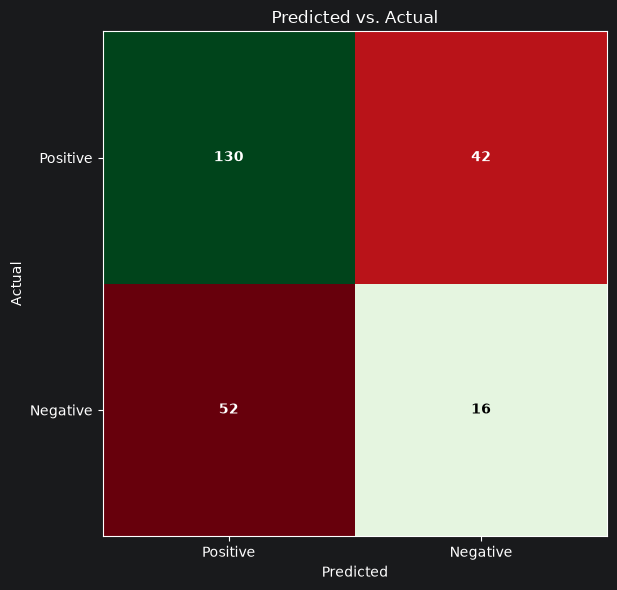

In [17]:
# TODO Assess the factors most responsible for determining a person's reading habits (PCA)
# TODO Determine the feasibility of a model for recommending books to a person according to their answers

def main():
    raw_data: pl.DataFrame = pl.read_csv("Lugeja25.tab", has_header=True, separator="\t")
    raw_data = raw_data.select(pl.exclude("INTNR", "ID", "weight")) # these won't be useful
    typed_data: tp.DataFrame[Answer] = tp.DataFrame(Answer, raw_data)
    # print(typed_data.head(1))
    # predict_habits(typed_data)
    q11_nulls_to_zero_data: tp.DataFrame[AnswerQ11NullsAsOnes] = typed_data.with_columns(typed_data.s.Q11_1.fill_null(strategy="one")).transform(AnswerQ11NullsAsOnes)
    # visualize_readership(data=q11_nulls_to_zero_data)

    l = predict_is_reader_parts_1_6(q11_nulls_to_zero_data)
    visualize_predict_is_reader(l)

    #v = predict_habits(data=q11_nulls_to_zero_data)
    #print(v)
    # visualize_predictions(v)

if __name__ == "__main__":
    main()